# សប្ដាហ៍ទី 5 · ការពិនិត្យ input

ទិន្នន័យចូលក្នុងប្រព័ន្ធតាមទ្វារមួយ: form មួយ file មួយ ឬសារមួយ។ សប្ដាហ៍នេះ អ្នកបង្កើតការពិនិត្យនៅមាត់ទ្វារនោះ ដើម្បីឱ្យទិន្នន័យមិនល្អត្រូវបានបដិសេធ ជាមួយមូលហេតុច្បាស់លាស់ មុនពេលវាអាចបង្កគ្រោះថ្នាក់។

| | |
|---|---|
| **សំណួរសប្ដាហ៍នេះ** | តើប្រព័ន្ធគួរធ្វើអ្វី ពេល input ខុស? |
| **Python ដែលអ្នកនឹងរៀន** | string method (`strip`, `lower`), `int()`, `try`/`except ValueError`, list នៃសារ error, ការ return value ពីរ |
| **គោលការណ៍ទី 5** | **កុំទុកចិត្ត input។** ពិនិត្យនៅមាត់ទ្វារ ពន្យល់បញ្ហាជាពាក្យសាមញ្ញ ហើយកុំប្ដូរអ្វីទាំងអស់ ពេល input មិនល្អ។ |
| **ផ្នែកដែលអ្នកបង្កើត** | `clean_offer(raw)`: វា return `(offer, errors)` សម្រាប់សំណើនីមួយៗដែលមកដល់ |

*Campus FoodBridge ជាករណីប្រឌិត។ អង្គការ មនុស្ស និងលេខទាំងអស់ សុទ្ធតែប្រឌិតឡើង។*

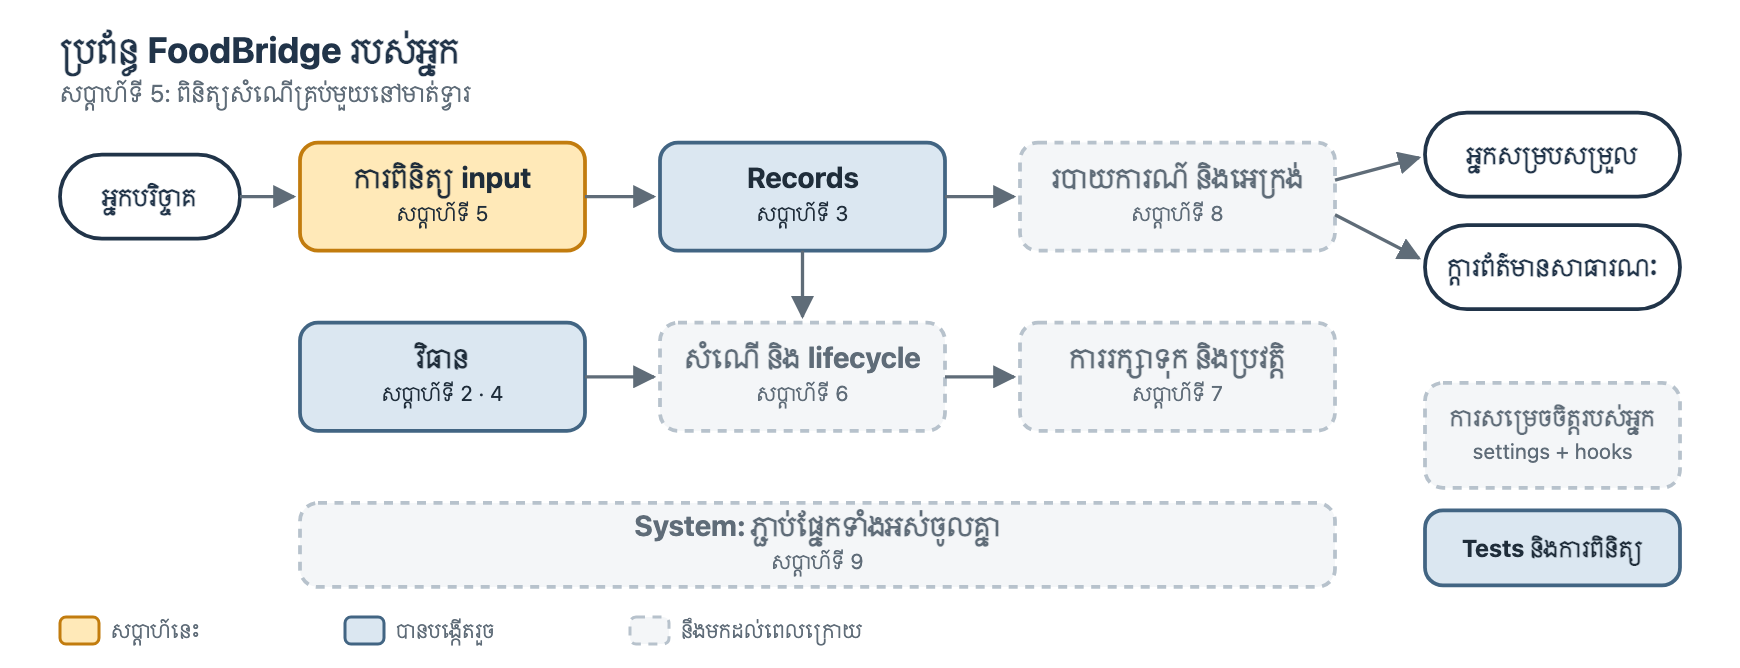

## មុនពេលចាប់ផ្ដើម

1. ចុចលើពាក្យ Copy to Drive (ឬ ចូលទៅកាន់ File រួចចុច Save a copy in Drive) រួចធ្វើការក្នុងច្បាប់ចម្លងរបស់អ្នក។
2. Run setup cell។ Run វាម្ដងទៀត ក្រោយពេល restart runtime។
3. ⭐ = កម្រិតមូលដ្ឋាន សម្រាប់គ្រប់គ្នា, ⭐⭐ = សម្រាប់សាកល្បងបន្ថែម។

In [ ]:
# @title ▶ សូម run cell នេះមុនគេ (setup) — វារៀបចំប្រព័ន្ធ FoodBridge
# វាដកយក (unpack) ប្រព័ន្ធរបស់វគ្គសិក្សា ដែលរក្សាទុកនៅក្នុង notebook នេះ។
# មិនត្រូវការ internet ឬ install អ្វីទេ។ សូម run វាម្ដងទៀត ក្រោយពេល Colab restart។
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("ឯកសាររបស់វគ្គសិក្សាក្នុង notebook នេះខូច។ សូមទាញយកច្បាប់ថ្មីមួយ។")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
bridge.set_language("km")     # screens and checks in Khmer
print("✅ ប្រព័ន្ធ FoodBridge រួចរាល់ហើយ (version " + bridge.KIT_VERSION + ")។ អ្នកអាចបន្តបាន។")


## ចាប់ផ្ដើមថ្នាក់ · ចែករំលែកកិច្ចការស្រាវជ្រាវទី 3 (10 នាទី)

ក្នុងក្រុមបីនាក់ ចែករំលែកការពិនិត្យ input ដែលអ្នកបានស្រាវជ្រាវ។

1. តើអ្នកបានសិក្សា form ឬប្រព័ន្ធណា? តើវាសុំឱ្យមនុស្សវាយ input អ្វីខ្លះ?
2. តើអ្នករកឃើញការពិនិត្យអ្វី? តើមនុស្សឃើញសារអ្វី ពេល input ខុស? តើសារនោះប្រើពាក្យសាមញ្ញឬទេ?
3. ប្រាប់ input មួយដែលវា **ទទួលយក ប៉ុន្តែគួរបដិសេធ** ឬ **បដិសេធ ប៉ុន្តែគួរទទួលយក**។ តើនរណាទទួលផលប៉ះពាល់?

📝 **គំនិតមួយពីមិត្តរួមថ្នាក់ ដែលខ្ញុំចង់ចងចាំ:**

## វគ្គទី 1 · រៀន: ការពិនិត្យ input នៅមាត់ទ្វារ (30 នាទី)

### គំនិតសំខាន់: គុណភាពទិន្នន័យនៅ boundary (ព្រំដែន)

នៅព្រលានយន្តហោះ បុគ្គលិកពិនិត្យលិខិតឆ្លងដែន និងសំបុត្ររបស់អ្នក **មុនពេល** អ្នកឡើងយន្តហោះ មិនមែនក្រោយពេលយន្តហោះហោះឡើងទេ។ ប្រព័ន្ធព័ត៌មានក៏ធ្វើការដូច្នេះដែរ។ value នីមួយៗចូលមកតាម **ទ្វារ** មួយ: form មួយ file មួយ ឬសារមួយ។ មាត់ទ្វារគឺជាកន្លែងដែលចំណាយតិចបំផុត ក្នុងការបញ្ឈប់ទិន្នន័យមិនល្អ។ ពេលទិន្នន័យមិនល្អចូលដល់ខាងក្នុងហើយ វារាលដាលទៅក្នុងផលបូក របាយការណ៍ និងការសម្រេចចិត្ត ហើយពិបាករកឃើញជាងមុនច្រើន។

មនុស្សមិនមែនធ្វេសប្រហែសដោយចេតនាទេ។ ពួកគេវាយ `many` ជំនួសឱ្យលេខ ថែមដកឃ្លាលើស ឬទុក field ទទេ។ ប្រព័ន្ធល្អរំពឹងទុករឿងនេះជាមុន។ វាពិនិត្យ value នីមួយៗ ប្រាប់មនុស្សឱ្យច្បាស់ថាត្រូវកែអ្វី ហើយមិនរក្សាទុកអ្វីទាំងអស់ រហូតដល់ input ត្រឹមត្រូវ។

### 1 · value គ្រប់មួយពី file គឺជា text

អ្នកបរិច្ចាគផ្ញើសំណើជាជួរៗ នៅក្នុង file CSV (តារាងសាមញ្ញមួយ ដែលរក្សាទុកជា text)។ kit អាន file នោះជំនួសអ្នក។ ជួរនីមួយៗក្លាយជា dictionary មួយ។

In [ ]:
rows = bridge.validation.read_offers_csv("foodbridge_kit/data/offers.csv")
print(len(rows), "rows")
print(rows[0])
print(type(rows[0]["portions"]))

មើល `'portions': '30'`។ សញ្ញាសម្រង់បង្ហាញថា `'30'` គឺជា **text** មិនមែនជាលេខទេ។ file CSV មានតែតួអក្សរប៉ុណ្ណោះ។ file មិនអាចប្រាប់ថា "មួយនេះជាលេខ" បានទេ។ មនុស្សម្នាក់បានវាយ `30` ហើយមនុស្សម្នាក់ទៀតអាចវាយ `many`។ ដូច្នេះ program ត្រូវតែពិនិត្យ និងបម្លែង value នីមួយៗដោយខ្លួនឯង។

🤔 Run cell បន្ទាប់។ រកជួរ **ប្រាំ** ដែលប្រព័ន្ធបានបដិសេធនៅមាត់ទ្វារ ក្នុងសប្ដាហ៍ទី 1។ តើជួរនីមួយៗខុសត្រង់ណា?

In [ ]:
for row in rows:
    print(row["donor"], "|", row["food"], "|", row["category"], "|",
          row["portions"], "portions |", row["hours_left"], "hours left")

📝 **ជួរដែលមើលទៅខុស និងមូលហេតុ:**

1.
2.
3.
4.
5.

ពេលខ្លះ key មួយបាត់ទាំងស្រុង ឧទាហរណ៍ ពេល web form មួយភ្លេច field មួយ។ ពេលនោះ `row["donor"]` នឹងឈប់ជាមួយ `KeyError`។ `row.get("donor", "")` មានសុវត្ថិភាពជាង: វាផ្ដល់ value ឬ `""` ពេល key បាត់។ អ្នកនឹងប្រើវាក្នុង P3 និងក្នុងផ្នែករបស់អ្នក។

```python
form = {"food": "Mango slices", "portions": "10"}   # គ្មាន key "donor"
form.get("donor", "")      # ផ្ដល់ "" ជំនួសឱ្យ KeyError
```

### 2 · រៀបចំ text ឱ្យស្អាត: `strip()` និង `lower()`

**method** គឺជា function ដែលជាកម្មសិទ្ធិរបស់ value មួយ។ អ្នកសរសេរវានៅក្រោយសញ្ញាចុច (dot)។ `strip()` លុបដកឃ្លានៅចុងទាំងសងខាង។ `lower()` ប្ដូរអក្សរទាំងអស់ទៅជាអក្សរតូច។ ទាំងពីរផ្ដល់ text **ថ្មី** មួយឱ្យអ្នក។ text ដើមមិនប្រែប្រួលទេ។

🤔 **ទាយមើល** បន្ទាត់នីមួយៗ រួច run។

In [ ]:
typed = "  Dara "                 # ឈ្មោះដែលវាយក្នុង login form
print(typed == "Dara")
print(typed.strip() == "Dara")
print(typed.strip().lower())
print(len(typed), len(typed.strip()))

CATEGORIES = ["bread", "rice meals", "fruit", "vegetables", "snacks"]
print(" Bread " in CATEGORIES)
print(" Bread ".strip().lower() in CATEGORIES)

**ការទាយ:** …  **លទ្ធផល:** …

បើមិនរៀបចំឱ្យស្អាតទេ `" Bread "` និង `"bread"` គឺជា text ខុសគ្នា ហើយប្រព័ន្ធនឹងគិតថាវាជាប្រភេទពីរផ្សេងគ្នា។ ពេលរៀបចំរួច ទាំងពីរក្លាយជា `"bread"` ហើយ `in` រកឃើញវានៅក្នុង list។

text method មួយទៀតដែលអ្នកនឹងជួបសប្ដាហ៍នេះ: `", ".join(words)` ភ្ជាប់ list នៃ text ទៅជា text តែមួយ ដោយមាន `, ` នៅចន្លោះ។ ឧទាហរណ៍ `", ".join(["bread", "fruit"])` ផ្ដល់ `"bread, fruit"`។

### 3 · `int()` ប្ដូរ text ទៅជាចំនួនគត់ ឬបរាជ័យ

អ្នកបានជួប `int()` រួចហើយនៅសប្ដាហ៍ទី 1។ វាក៏មិនខ្វល់ពីដកឃ្លានៅចុងទាំងសងខាងដែរ។ ប៉ុន្តែពេល text មិនមែនជាចំនួនគត់ វាបញ្ឈប់ program ជាមួយ `ValueError`។

In [ ]:
print(int("30") + 4)
print(int(" 12 "))
print(int("-3"))
# print(int("many"))     # លុប # ចេញ ដើម្បីមើល error រួចដាក់វាវិញ

🤔 តើ value ណាខ្លះដំណើរការជាមួយ `int()`: `"7"`, `"seven"`, `"7.5"`, `""`? សាកល្បងវានៅក្នុង cell ខាងលើ។

**ចម្លើយរបស់ខ្ញុំ:** …

សូមកត់សម្គាល់ថា `int("-3")` ដំណើរការ។ `-3` **ជា** ចំនួនគត់ ប៉ុន្តែវាមិនមែនជាចំនួនចំណែកដែលសមហេតុផលទេ។ ការបម្លែងគឺជាការពិនិត្យមួយ។ **range** (តើវានៅចន្លោះដែនកំណត់ឬទេ?) គឺជាការពិនិត្យទីពីរ។

### 4 · `try` / `except ValueError`: គ្រោងទុកសម្រាប់បញ្ហា

ពេលអ្នក **រំពឹងទុក** ថានឹងមានបញ្ហា អ្នកអាចគ្រោងទុកសម្រាប់វាបាន។ Python run បន្ទាត់ដែលនៅក្រោម `try`។ បើបន្ទាត់ណាមួយ raise `ValueError` នោះ Python លោតទៅ `except` ជំនួសឱ្យការឈប់។

In [ ]:
quantity_text = "two"           # វាយក្នុង order form របស់ហាងទូរស័ព្ទ
try:
    quantity = int(quantity_text)
    print("Order for", quantity, "phones")
except ValueError:
    print("Please type the quantity as a number, for example 2.")

🤔 ប្ដូរ `"two"` ទៅជា `"2"` ហើយទាយលទ្ធផល មុនពេលអ្នក run។

**ការទាយ:** …  **លទ្ធផល:** …

ទម្លាប់ល្អពីរ:

- ទុក `try` ឱ្យ **តូច**: មានតែបន្ទាត់ដែលអាចបរាជ័យ (ការបម្លែង)។
- ចាប់ **តែ** `ValueError` ដែលជាបញ្ហាដែលអ្នករំពឹងទុក។ កំហុសផ្សេងទៀតក្នុង code របស់អ្នក គួរតែនៅតែបង្ហាញ ដើម្បីឱ្យអ្នកអាចកែវាបាន។

### 5 · list នៃសារ error

ស្រមៃមើល form មួយដែលបង្ហាញតែបញ្ហាទីមួយប៉ុណ្ណោះ។ អ្នកបរិច្ចាគកែវា ផ្ញើម្ដងទៀត ហើយទទួលបានបញ្ហាបន្ទាប់។ នោះខាតពេលវេលា។ ទ្វារដែលល្អជាងនេះ ពិនិត្យ **គ្រប់យ៉ាង** ប្រមូលបញ្ហាទាំងអស់ទៅក្នុង list មួយ ហើយពន្យល់បញ្ហានីមួយៗជាពាក្យសាមញ្ញ។

In [ ]:
name = "  "
age_text = "seventeen"
errors = []

if name.strip() == "":
    errors.append("name is required.")
try:
    age = int(age_text)
except ValueError:
    errors.append("age must be a whole number, for example 19.")

print(errors)
print(len(errors), "problem(s)")

ប្រៀបធៀបសារផ្ទាល់របស់ Python `invalid literal for int() with base 10: 'many'` ជាមួយ `portions must be a whole number, for example 12.`។ អ្នកដែលអានសារទាំងនេះ គឺអ្នកបរិច្ចាគ មិនមែនអ្នកសរសេរ program ទេ។ ប្រាប់ **អ្វី** ដែលខុស និង **របៀប** កែវា។

### 6 · return value ពីរ រួច unpack វា

function មួយអាចបញ្ជូន value ពីរមកវិញក្នុងពេលតែមួយ: `return age, errors`។ អ្នកដែលហៅ function **unpack** value ទាំងនោះទៅក្នុងឈ្មោះពីរ: `age, errors = check_age("17")`។ value ទីមួយចូលទៅក្នុងឈ្មោះទីមួយ value ទីពីរចូលទៅក្នុងឈ្មោះទីពីរ។

In [ ]:
def check_age(age_text):
    """Return (age, errors). age is None when there is a problem."""
    try:
        age = int(age_text)
    except ValueError:
        return None, ["age must be a whole number, for example 19."]
    if age < 16:
        return None, ["volunteers must be 16 or older."]
    return age, []

age, errors = check_age("17")
print(age, errors)

🤔 **ទាយមើល** ថា `check_age("abc")` និង `check_age("12")` return អ្វី។ បន្ទាប់មក បន្ថែមពីរបន្ទាត់ទៅក្នុង cell ហើយពិនិត្យ។

**ការទាយ:** …  **លទ្ធផល:** …

នេះគឺជារូបរាងនៃផ្នែករបស់អ្នកសប្ដាហ៍នេះ: value ល្អមួយជាមួយ list ទទេ **ឬ** `None` ជាមួយ list នៃបញ្ហា។ មិនដែលមានទាំងពីរក្នុងពេលតែមួយទេ។ `None` មានន័យថា "គ្មានសំណើត្រូវបានបង្កើតទេ" ដូច្នេះគ្មានអ្វីក្នុងប្រព័ន្ធប្រែប្រួលឡើយ។ នោះហើយគឺផ្នែកទាំងបីនៃគោលការណ៍ទី 5: ពិនិត្យនៅមាត់ទ្វារ ពន្យល់ជាពាក្យសាមញ្ញ កុំប្ដូរអ្វីទាំងអស់។

## វគ្គទី 2 · អនុវត្ត និងវាយតម្លៃ (60 នាទី)

### ⭐ P1 · ទាយ text ដែលបានរៀបចំ

សរសេរការទាយរបស់អ្នកសម្រាប់បន្ទាត់នីមួយៗ រួច run។

In [ ]:
print(" Rice Meals ".strip())
print(" Rice Meals ".lower())
print(" Rice Meals ".strip().lower() == "rice meals")
print("   ".strip() == "")
print(len("  bread  ".strip()))

**ការទាយ:** …  **លទ្ធផល:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

`Rice Meals`, ` rice meals ` (ដកឃ្លានៅដដែល ព្រោះ `lower()` ប្ដូរតែអក្សរប៉ុណ្ណោះ), `True`, `True`, `5`។ បន្ទាត់ទីបួនគឺជារបៀប test field ទទេ: value ដែលមានតែដកឃ្លា នៅតែជា field ទទេ។

</details>

### ⭐ P2 · ជួសជុល crash

program របស់គ្រូម្នាក់ អានពិន្ទុប្រឡងដែលជំនួយការវាយបញ្ចូល។ `int("absent")` ធ្វើឱ្យវា crash។ សរសេរ `read_mark(text)` ដើម្បីឱ្យវា return ពិន្ទុជា `int` ឬ `None` ពេល text មិនមែនជាចំនួនគត់។ ដាក់តែការបម្លែងប៉ុណ្ណោះនៅក្នុង `try`។

In [ ]:
def read_mark(text):
    """Return the mark as an int, or None when text is not a whole number."""
    # TODO: សាក int(text); ក្នុង except ValueError ឱ្យ return None
    return None

print(read_mark("75"), read_mark(" 80 "), read_mark("absent"), read_mark(""))

លទ្ធផលដែលរំពឹងទុក: `75 80 None None`។

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
def read_mark(text):
    try:
        return int(text)
    except ValueError:
        return None
```

`None` មានន័យថា "គ្មាន value"។ អ្នកដែលហៅ function អាច test `if mark is None:` ហើយសម្រេចថាត្រូវនិយាយអ្វី។ program មិនឈប់ទេ ហើយវាក៏មិនធ្វើពុតថា `"absent"` ជាលេខដែរ។

</details>

### ⭐ P3 · ប្រមូល field ទាំងអស់ដែលបាត់

form ចុះឈ្មោះអ្នកស្ម័គ្រចិត្ត ត្រូវតែមានឈ្មោះ លេខទូរស័ព្ទ និងមហាវិទ្យាល័យ។ loop លើ `REQUIRED` ហើយបន្ថែមសារមួយ សម្រាប់ field ទទេ **នីមួយៗ**។ ចាំថា value ដែលមានតែដកឃ្លា គឺទទេ។

In [ ]:
REQUIRED = ["name", "phone", "faculty"]
form = {"name": "Sokha", "phone": "   ", "faculty": ""}

errors = []
for field in REQUIRED:
    value = form.get(field, "")
    # TODO: បើ value ទទេក្រោយ strip() បន្ថែម field + " is required." ទៅក្នុង errors

print(errors)

លទ្ធផលដែលរំពឹងទុក: `['phone is required.', 'faculty is required.']`។ ឥឡូវលុប key `"faculty"` ចេញពី `form` ហើយ run ម្ដងទៀត។ ហេតុអ្វីបានជា code នៅតែដំណើរការ?

**ចម្លើយរបស់ខ្ញុំ:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
for field in REQUIRED:
    value = form.get(field, "")
    if value.strip() == "":
        errors.append(field + " is required.")
```

បើគ្មាន key នោះ `form.get("faculty", "")` ផ្ដល់ `""` ដូច្នេះ field នោះត្រូវបានរាយការណ៍ថាត្រូវតែបំពេញ ជំនួសឱ្យការ crash ជាមួយ `KeyError`។ `clean_offer` របស់អ្នកប្រើ loop ដូចគ្នានេះ សម្រាប់ `REQUIRED_FIELDS`។

</details>

### ⭐ P4 · value ពីរត្រឡប់មកវិញ

form បញ្ចូលទំនិញរបស់ហាងមួយ ត្រូវការបរិមាណពី 1 ដល់ 500។ សរសេរ `clean_quantity(text)` ដែល return `(quantity, errors)`:

- មិនមែនជាចំនួនគត់ → `(None, ["quantity must be a whole number."])`
- នៅក្រៅ 1 ដល់ 500 → `(None, ["quantity must be between 1 and 500."])`
- ក្រៅពីនេះ → `(quantity, [])`

In [ ]:
MIN_QUANTITY = 1
MAX_QUANTITY = 500

def clean_quantity(text):
    # TODO: បម្លែងដោយប្រើ try/except រួចពិនិត្យ range
    return None, ["not done yet"]

quantity, errors = clean_quantity("40")
print(quantity, errors)
quantity, errors = clean_quantity("lots")
print(quantity, errors)
quantity, errors = clean_quantity("900")
print(quantity, errors)

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
def clean_quantity(text):
    try:
        quantity = int(text)
    except ValueError:
        return None, ["quantity must be a whole number."]
    if quantity < MIN_QUANTITY or quantity > MAX_QUANTITY:
        return None, [f"quantity must be between {MIN_QUANTITY} and {MAX_QUANTITY}."]
    return quantity, []
```

លទ្ធផលដែលរំពឹងទុក: `40 []` បន្ទាប់មក `None ['quantity must be a whole number.']` បន្ទាប់មក `None ['quantity must be between 1 and 500.']`។ test boundary ផងដែរ: `"1"` និង `"500"` ត្រូវបានទទួលយក ចំណែក `"0"` និង `"501"` មិនត្រូវបានទទួលយកទេ។

</details>

### ⭐⭐ S1 · លេខដែលគួរឱ្យភ្ញាក់ផ្អើល

`int()` ទទួលយកច្រើនជាងអ្វីដែលអ្នកប្រហែលជារំពឹង។ ទាយ រួច run។ សម្រាប់ value នីមួយៗ សម្រេចចិត្ត: **តើប្រព័ន្ធ FoodBridge គួរទទួលយកវាជាចំនួនចំណែកឬទេ?** គ្មានចម្លើយត្រឹមត្រូវតែមួយទេ។ សូមផ្ដល់មូលហេតុ។

In [ ]:
for text in ["១២", "+5", "1_000", "12.0", "1,200", "0"]:
    try:
        print(repr(text), "→", int(text))     # repr() បង្ហាញសញ្ញាសម្រង់
    except ValueError:
        print(repr(text), "→ ValueError")

**ការសម្រេចចិត្ត និងមូលហេតុរបស់ខ្ញុំ:** …

### ⚖️ ល្អ ឬមានហានិភ័យ?

អ្នកបានសួរជំនួយការ AI មួយថា: *"សរសេរ Python ដែលអានសំណើពី file CSV ហើយរក្សាទុកវា។"* វាផ្ដល់ឱ្យអ្នកនូវ **Version A**។ ពេល A crash នៅជួរ cupcakes អ្នកបាននិយាយថា *"វា crash"* ហើយវាផ្ដល់ឱ្យអ្នកនូវ **Version B**: *"កែរួចហើយ! ឥឡូវវានឹងមិន crash ទៀតទេ។"*

**Version A**

```python
saved_offers = []

def add_offer(raw):
    offer = {
        "donor": raw["donor"],
        "food": raw["food"],
        "category": raw["category"],
        "portions": int(raw["portions"]),
        "hours_left": int(raw["hours_left"]),
    }
    saved_offers.append(offer)
    return "OK"
```

**Version B**

```python
saved_offers = []

def add_offer(raw):
    offer = {"donor": raw["donor"], "food": raw["food"]}
    saved_offers.append(offer)               # រក្សាទុកភ្លាមៗ
    try:
        offer["portions"] = int(raw["portions"])
    except:
        offer["portions"] = 0                # មិន crash ដាច់ខាត
    try:
        offer["hours_left"] = int(raw["hours_left"])
    except:
        offer["hours_left"] = 0
    if raw["category"] not in CATEGORIES:
        return "error"
    offer["category"] = raw["category"]
    return "OK"
```

Run Version B លើ file គំរូ ហើយអានអ្វីដែលវាបានរក្សាទុក។

In [ ]:
CATEGORIES = ["bread", "rice meals", "fruit", "vegetables", "snacks"]
saved_offers = []

def add_offer(raw):
    offer = {"donor": raw["donor"], "food": raw["food"]}
    saved_offers.append(offer)               # រក្សាទុកភ្លាមៗ
    try:
        offer["portions"] = int(raw["portions"])
    except:
        offer["portions"] = 0                # មិន crash ដាច់ខាត
    try:
        offer["hours_left"] = int(raw["hours_left"])
    except:
        offer["hours_left"] = 0
    if raw["category"] not in CATEGORIES:
        return "error"
    offer["category"] = raw["category"]
    return "OK"

for row in rows:
    print(add_offer(row), "·", row["food"])
print(len(saved_offers), "offers saved:")
for offer in saved_offers:
    print(offer)

ប្រើ **គោលការណ៍ទី 5 (កុំទុកចិត្ត input)**។ តើ B ល្អជាង A ឬទេ? រកបញ្ហា **យ៉ាងហោចណាស់បី** ក្នុង B។ សម្រាប់បញ្ហានីមួយៗ ប្រាប់ថាសំណើណា ឬមនុស្សណា ដែលរងគ្រោះ។

📝 **បញ្ហាដែលខ្ញុំរកឃើញ:**

1.
2.
3.

**តើ B ល្អជាង A ឬទេ? ហេតុអ្វី?**

<details><summary>មតិរបស់គ្រូ</summary>

**Version A** បរាជ័យយ៉ាងច្បាស់ ដែលគ្រប់គ្នាឃើញ។ នៅជួរ cupcakes, `int("many")` បញ្ឈប់ program ទាំងមូល។ Student Club Bake Sale មិនទទួលបានចម្លើយទេ ហើយជួរបីបន្ទាប់ពីវា (corn, rice, mango) មិនដែលត្រូវបានអានឡើយ។ A ក៏ទទួលយកអ្វីៗដែលបម្លែងបានដែរ: វារក្សាទុក noodle soup ក្នុងប្រភេទដែលមិនមាន ហើយបើ rice 1200 ចំណែក ឬជួរ mango ដែលគ្មានអ្នកបរិច្ចាគ នៅមុន cupcakes នោះវានឹងរក្សាទុកជួរទាំងនោះផងដែរ។

**Version B** មិនដែល crash ទេ ប៉ុន្តែវា **ខុសដោយស្ងាត់ៗ**:

1. **value មិនល្អក្លាយជា 0។** cupcakes "many" របស់ Student Club ត្រូវបានរក្សាទុកជា 0 ចំណែក។ ក្លឹបនោះគិតថាសំណើរបស់ខ្លួនត្រូវបានទទួលយក ហើយគ្មានអ្នកស្ម័គ្រចិត្តណាទៅយកអាហារពិតនោះទេ។
2. **សំណើពាក់កណ្ដាលត្រូវបានរក្សាទុក។** noodle soup ត្រូវបានបញ្ចូលទៅក្នុង `saved_offers` **មុន** ការពិនិត្យប្រភេទ។ B return `"error"` ប៉ុន្តែ record ដែលគ្មានប្រភេទនៅតែនៅទីនោះ។ របាយការណ៍ទាំងអស់នៅពេលក្រោយ ត្រូវតែដោះស្រាយជាមួយវា។
3. **សារមិនប្រាប់អ្វីសោះ។** `"error"` មិនប្រាប់ Riverside Restaurant ថាត្រូវកែអ្វីទេ។
4. **`except:` ទទេ (bare)** លាក់បញ្ហាទាំងអស់ សូម្បីតែការវាយខុសក្នុង code ដូច្នេះ bug ក្លាយជារបស់មើលមិនឃើញ។
5. **នៅតែគ្មានដែនកំណត់។** 1200 ចំណែក និង 0 ម៉ោងនៅសល់ ត្រូវបានទទួលយក ហើយសំណើ mango គ្មានអ្នកបរិច្ចាគសម្រាប់ទូរស័ព្ទទៅទេ។

B មានគ្រោះថ្នាក់ **ជាង** A។ crash គួរឱ្យរំខាន ប៉ុន្តែគ្រប់គ្នាកត់សម្គាល់ឃើញវា។ ចម្លើយខុសដោយស្ងាត់ៗ ចូលទៅក្នុងផលបូក ហើយមនុស្សធ្វើសកម្មភាពតាមវា។ ទ្វារដែលមានសុវត្ថិភាព ធ្វើការបួនយ៉ាង: រៀបចំ text ឱ្យស្អាត ពិនិត្យ **គ្រប់យ៉ាង** ហើយប្រមូលបញ្ហាទាំងអស់ បង្កើតសំណើ **តែ** ពេល list ទទេ និងពន្យល់បញ្ហានីមួយៗជាពាក្យសាមញ្ញ។ នោះហើយជាផ្នែករបស់អ្នកក្នុងវគ្គទី 3។

</details>

## វគ្គទី 3 · បង្កើតផ្នែករបស់អ្នក: ការពិនិត្យនៅមាត់ទ្វារ (60–80 នាទី)

សំណើនីមួយៗចូលក្នុងប្រព័ន្ធតាមរយៈ `add_offer`។ មុនពេលវាបង្កើត record ប្រព័ន្ធហៅ `clean_offer(raw)`។ មនុស្សបីក្រុមពឹងផ្អែកលើវា:

- **អ្នកបរិច្ចាគ** អានសារ ហើយកែសំណើ;
- **អ្នកសម្របសម្រួល** ទទួលបាន record ស្អាតៗ ដែលមានលេខពិតប្រាកដ;
- **របាយការណ៍** បង្ហាញផលបូកដែលស្មោះត្រង់ (សប្ដាហ៍ទី 8)។

ការសន្យា (contract) របស់ `clean_offer(raw)`:

| Input | Return |
|---|---|
| ជួរល្អ | `(offer, [])`: text ត្រូវបាន strip, category ជាអក្សរតូច, `portions` និង `hours_left` ជា `int` |
| ជួរមិនល្អ | `(None, [every problem in plain words])`: បញ្ហាទាំងអស់ ជាពាក្យសាមញ្ញ |

### ដែនកំណត់របស់អ្នក (constant)

ទាំងនេះជាការសម្រេចចិត្តរបស់អ្នកសម្របសម្រួល។ សូមរក្សា default សិនសម្រាប់ពេលនេះ។ អ្នកនឹងជ្រើសរើសដែនកំណត់ផ្ទាល់ខ្លួននៅចុងបញ្ចប់។

In [ ]:
MIN_PORTIONS = 1
MAX_PORTIONS = 200
REJECT_IF_HOURS_LEFT_BELOW = 1
CATEGORIES = ["bread", "rice meals", "fruit", "vegetables", "snacks"]
REQUIRED_FIELDS = ["donor", "food", "category", "portions", "hours_left"]

### ជំហានទី 1 · helper មួយដែលបម្លែងចំនួនគត់

នេះជាលំនាំដូចគ្នានឹង `read_mark` ក្នុង P2។

In [ ]:
def to_whole_number(text):
    """Return text as an int, or None when it is not a whole number."""
    # TODO 1: សាក int(text); ក្នុង except ValueError ឱ្យ return None
    return None

print(to_whole_number("30"), to_whole_number(" 5 "), to_whole_number("many"), to_whole_number(""))

លទ្ធផលដែលរំពឹងទុក: `30 5 None None`។

### ជំហានទី 2 · `clean_offer`

ភាគច្រើននៃ function នេះ ត្រូវបានសរសេររួចសម្រាប់អ្នក។ បំពេញ `TODO` ទាំងបី។ អាន comment: វាប្រាប់អ្នកឱ្យច្បាស់ថា ផ្នែកនីមួយៗត្រូវធ្វើអ្វី។

In [ ]:
def clean_offer(raw):
    """Check one raw row at the door.

    Return (offer, []) for a good row, or (None, errors) for a bad row.
    """
    errors = []

    # TODO 2: រៀបចំ text ឱ្យស្អាត។ បន្ថែម .strip() ទៅបន្ទាត់ទាំងបួន ហើយ .lower() សម្រាប់ category ផង។
    donor = raw.get("donor", "")
    contact = raw.get("contact", "")
    food = raw.get("food", "")
    category = raw.get("category", "")

    # field ដែលត្រូវតែបំពេញ មិនអាចទទេបានទេ (សរសេររួចសម្រាប់អ្នក ដូច P3)។
    for field in REQUIRED_FIELDS:
        if raw.get(field, "").strip() == "":
            errors.append(field + " is required.")

    # លេខ: helper របស់អ្នកប្ដូរ text ទៅជា int ឬ None។
    portions = to_whole_number(raw.get("portions", ""))
    hours_left = to_whole_number(raw.get("hours_left", ""))

    # TODO 3: ពិនិត្យ range។ បន្ថែម elif មួយនៅក្រោម if នីមួយៗ:
    #   portions តិចជាង MIN_PORTIONS ឬលើស MAX_PORTIONS
    #       -> "portions must be between ... and ..."
    #   hours_left តិចជាង REJECT_IF_HOURS_LEFT_BELOW
    #       -> "too late to collect: ... hours left, the minimum is ..."
    if portions is None:
        errors.append("portions must be a whole number, for example 12.")
    if hours_left is None:
        errors.append("hours_left must be a whole number of hours.")

    # TODO 4: បើ category មិននៅក្នុង CATEGORIES បន្ថែម
    #   "category must be one of: bread, rice meals, ..."  (ជំនួយ: ", ".join(CATEGORIES))

    if errors:
        return None, errors        # កុំប្ដូរអ្វីទាំងអស់: គ្មានសំណើសោះ
    offer = {"donor": donor, "contact": contact, "food": food, "category": category,
             "portions": portions, "hours_left": hours_left}
    return offer, []

សាកល្បងវាលើជួរមួយដែលរញ៉េរញ៉ៃ ប៉ុន្តែល្អ និងលើជួរមួយដែលមានបញ្ហាបី។

In [ ]:
messy = {"donor": " Lotus Cafe ", "contact": "lotus@example.org", "food": "Steamed buns",
         "category": " Snacks ", "portions": " 15 ", "hours_left": "3"}
print(clean_offer(messy))

bad = {"donor": "Lotus Cafe", "food": "Soup", "category": "soup",
       "portions": "-3", "hours_left": "soon"}
print(clean_offer(bad))

ពេលអ្នកធ្វើរួច បន្ទាត់ទីមួយបង្ហាញ dictionary មួយដែលមាន `'category': 'snacks'` និង `'portions': 15` (គ្មានសញ្ញាសម្រង់: ជាលេខ) តាមពីក្រោយដោយ `[]`។ បន្ទាត់ទីពីរបង្ហាញ `None` និងសារ **បី**។

### ពិនិត្យវា

checker សាកល្បងជួរល្អមួយដែលមានដកឃ្លាលើស បន្ទាប់មកសាក value មិនល្អម្ដងមួយៗ។ វាប្រើដែនកំណត់ **របស់អ្នក** ដូច្នេះវានៅតែដំណើរការ ក្រោយពេលអ្នកប្ដូរដែនកំណត់ទាំងនោះ។

In [ ]:
MY_SETTINGS = {
    "MIN_PORTIONS": MIN_PORTIONS,
    "MAX_PORTIONS": MAX_PORTIONS,
    "REJECT_IF_HOURS_LEFT_BELOW": REJECT_IF_HOURS_LEFT_BELOW,
    "CATEGORIES": CATEGORIES,
    "REQUIRED_FIELDS": REQUIRED_FIELDS,
}
bridge.check("clean_offer", clean_offer, MY_SETTINGS)

🤔 ស្រមៃមើល `clean_offer` មួយដែលបដិសេធគ្រប់ជួរ: `return None, ["no"]`។ តើវាជាប់ប៉ុន្មានករណី ក្នុងចំណោម 7 ករណី? ករណីណាចាប់វាបាន ហើយហេតុអ្វីករណីនោះសំខាន់?

**ចម្លើយរបស់ខ្ញុំ:** …

### ភ្ជាប់វាចូលប្រព័ន្ធ

ឥឡូវទ្វាររបស់អ្នកការពារប្រព័ន្ធពិត។ មើលជំហានទី 1 នៃថ្ងៃ: បន្ទាត់ 🚫 នីមួយៗ គឺជាជួរដែល `clean_offer` **របស់អ្នក** បានបដិសេធ ជាមួយសារ **របស់អ្នក**។

In [ ]:
my_system = bridge.System(MY_SETTINGS, hooks={"clean_offer": clean_offer})
my_system.run_day()

ការបដិសេធ ត្រូវតែមិនប្ដូរអ្វីទាំងអស់។ សាកល្បងវា: បញ្ចូលសំណើមិនល្អមួយ ហើយប្រៀបធៀប record មុន និងក្រោយ។ បន្ទាប់មក បញ្ចូលសំណើដែលរញ៉េរញ៉ៃ ប៉ុន្តែល្អ ពីខាងលើ។

In [ ]:
before = my_system.records()
offer_id, errors = my_system.add_offer({"donor": "Hotel Kitchen", "contact": "hotel@example.org",
                                        "food": "Steamed rice", "category": "Rice Meals",
                                        "portions": "-3", "hours_left": "8"})
print("Bad offer →", offer_id, errors)
print("Records unchanged:", my_system.records() == before)

offer_id, errors = my_system.add_offer(messy)
print("Messy but good offer →", offer_id, errors)
for record in my_system.records():
    print("  ", record["id"], "·", record["food"], "·", record["category"], "·", record["portions"], "portions")

### 🧭 ការសម្រេចចិត្តរបស់អ្នក · តើទ្វារទទួលយកអ្វីខ្លះ?

អ្នកសម្របសម្រួលស្នើឱ្យអ្នកកំណត់ដែនកំណត់របស់ទ្វារ។ ដែនកំណត់នីមួយៗការពារនរណាម្នាក់ ហើយបដិសេធនរណាម្នាក់។

- **`MIN_PORTIONS` / `MAX_PORTIONS`:** តើសំណើ 1 ចំណែក សមនឹងការធ្វើដំណើររបស់អ្នកស្ម័គ្រចិត្តឬទេ? តើមានអង្គការដៃគូណាអាចទទួល 200 ចំណែកបានទេ?
- **`REJECT_IF_HOURS_LEFT_BELOW`:** ពេលនៅសល់ 1 ម៉ោង តើអ្នកស្ម័គ្រចិត្តនៅទាន់ទៅដល់ទេ?
- **`REQUIRED_FIELDS`:** តើ field ណាខ្លះដែលអ្នកបរិច្ចាគត្រូវតែបំពេញ? ឧទាហរណ៍ **តើ `contact` គួរតែជា field ដែលត្រូវតែបំពេញឬទេ?** បើមានព័ត៌មានទំនាក់ទំនង ក្រុមការងារអាចរៀបចំការទៅយក ហើយទូរស័ព្ទទៅពេលមានបញ្ហា។ ប៉ុន្តែពេលនោះ ប្រព័ន្ធរក្សាទុកទិន្នន័យផ្ទាល់ខ្លួនច្រើនជាងមុន ដែលវាត្រូវតែការពារ (សប្ដាហ៍ទី 8) ហើយអ្នកបរិច្ចាគតូចៗខ្លះ អាចឈប់ផ្ដល់អាហារ។

1. ប្ដូរ constant នៅក្នុង **ដែនកំណត់របស់អ្នក** ខាងលើ។ អ្នកអាចរក្សា default បាន បើអ្នកអាចពន្យល់ពីមូលហេតុ។
2. Run ម្ដងទៀត ចាប់ពី cell នោះ ចុះមកដល់ទីនេះ។ ការពិនិត្យនៅតែជាប់ ព្រោះវាប្រើដែនកំណត់របស់អ្នក។
3. Run cell ខាងក្រោម ដើម្បីមើលថាទ្វាររបស់អ្នកធ្វើអ្វីជាមួយថ្ងៃគំរូ។

In [ ]:
for row in bridge.validation.read_offers_csv("foodbridge_kit/data/offers.csv"):
    offer, errors = clean_offer(row)
    if errors:
        print("🚫", row["food"], "→", " ".join(errors))
    else:
        print("✅", offer["food"], "·", offer["portions"], "portions ·", offer["hours_left"], "hours left")

📝 **កំណត់ត្រាការសម្រេចចិត្ត (decision log) · សប្ដាហ៍ទី 5**

| | |
|---|---|
| **ជម្រើសរបស់ខ្ញុំ** | ចំណែកពី … ដល់ …; បដិសេធពេលនៅសល់តិចជាង … ម៉ោង; ត្រូវតែបំពេញ: … |
| **ជម្រើសផ្សេងដែលខ្ញុំបានពិចារណា** | |
| **មូលហេតុដែលខ្ញុំជ្រើសរើសវា** | |
| **នរណាទទួលផលប៉ះពាល់ (ការដោះដូរ ឬ trade-off)** | |

### ⭐⭐ បន្ថែម · សារតែមួយសម្រាប់អ្នកបរិច្ចាគ

list ល្អសម្រាប់ program ប៉ុន្តែអ្នកបរិច្ចាគចង់បានសារដ៏រួសរាយតែមួយ។ សរសេរ `message_for_donor(errors)` ដែល return text ដូចជា `"Sorry, we could not accept your offer: 1) portions must be ... 2) category must be ..."` ឬ `"Thank you, your offer was accepted."` ពេល list ទទេ។

In [ ]:
def message_for_donor(errors):
    return "?"

offer, errors = clean_offer(bad)
print(message_for_donor(errors))
print(message_for_donor([]))

## បញ្ចប់

- [ ] ខ្ញុំបានចែករំលែកលទ្ធផលកិច្ចការស្រាវជ្រាវទី 3 របស់ខ្ញុំ ក្នុងពេលចាប់ផ្ដើមថ្នាក់។
- [ ] `read_mark` និង `clean_quantity` របស់ខ្ញុំ បដិសេធ text មិនល្អ ដោយមិន crash។
- [ ] ខ្ញុំបានរកឃើញបញ្ហាយ៉ាងហោចណាស់បីក្នុង Version B ហើយខ្ញុំអាចពន្យល់ថា ហេតុអ្វី "ខុសដោយស្ងាត់ៗ" អាក្រក់ជាង crash។
- [ ] `clean_offer` ជាប់ការពិនិត្យទាំងអស់ ហើយ `run_day()` បង្ហាញទ្វាររបស់ខ្ញុំបដិសេធជួរដោយ 🚫។
- [ ] កំណត់ត្រាការសម្រេចចិត្តរបស់ខ្ញុំ ពន្យល់ពីដែនកំណត់ និង field ដែលត្រូវតែបំពេញ។

### កិច្ចការស្រាវជ្រាវទី 4 · របៀបដែលប្រព័ន្ធរក្សាទិន្នន័យ និងប្រវត្តិ (5%)

ជ្រើសរើសប្រព័ន្ធពិតមួយដែលរក្សា record តាមពេលវេលា: របាយការណ៍គណនីធនាគារ (bank statement) record សាលារបស់អ្នក ប្រវត្តិការហៅក្នុងទូរស័ព្ទ ឬគណនីបណ្ណាល័យ។

1. **តើរក្សាទុកអ្វីខ្លះ?** រាយទិន្នន័យសំខាន់ៗក្នុង record មួយ។
2. **តើប្រើ ID អ្វីខ្លះ?** ឧទាហរណ៍ លេខគណនី ឬ student ID។ ហេតុអ្វី record នីមួយៗត្រូវការ ID មួយ?
3. **តើមានអ្វីកើតឡើង ពេលមានការកែតម្រូវ?** តើ value ចាស់ត្រូវបានរក្សាទុក ត្រូវបានជំនួស ឬបង្ហាញថាជាការកែតម្រូវ? តើអ្នកដឹងដោយរបៀបណា?
4. **តើនរណាត្រូវការប្រវត្តិ** ហើយហេតុអ្វី?

ពិពណ៌នាប្រភេទទិន្នន័យ។ កុំចម្លងលេខពិត ឬព័ត៌មានផ្ទាល់ខ្លួនរបស់អ្នកផ្ទាល់។ ប្រើប្រភពយ៉ាងហោចណាស់មួយ ហើយប្រាប់ឈ្មោះវា។ បើអ្នកប្រើជំនួយការ AI បង្ហាញកន្លែងមួយដែលអ្នកបានពិនិត្យ ឬកែវា។ យកឧទាហរណ៍របស់អ្នកមក **ចាប់ផ្ដើមថ្នាក់សប្ដាហ៍ទី 6**។ ដាក់ស្នើ (submit) តាម email ទៅ submit.progmis@gmail.com; ថ្ងៃផុតកំណត់ និងឈ្មោះ file នឹងត្រូវប្រកាសក្នុងថ្នាក់។

**សប្ដាហ៍ក្រោយ:** សំណើដែលស្អាតហើយ នៅតែមានដំណើររបស់វា: ថ្មី បានអនុម័ត បានទៅយក បានប្រគល់។ អ្នកនឹងធ្វើឱ្យប្រាកដថា វាអាចប្ដូរបានតែតាមផ្លូវត្រឹមត្រូវប៉ុណ្ណោះ។